In [1]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42,
    max_depth=20,
    min_samples_leaf=5
)

In [2]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [3]:
TRAIN_PATH = "../data/splits/train.parquet"
TEST_PATH = "../data/splits/test.parquet"

train_df = pd.read_parquet(TRAIN_PATH)
test_df = pd.read_parquet(TEST_PATH)

print(f"Training rows: {len(train_df):,}")
print(f"Testing rows:  {len(test_df):,}")
print(f"Training columns: {len(train_df.columns)}")

Training rows: 1,785,012
Testing rows:  446,254
Training columns: 70


In [4]:
TARGET = "BinaryLabel"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET]

X_test = test_df.drop(columns=[TARGET])
y_test = test_df[TARGET]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

X_train: (1785012, 69)
X_test:  (446254, 69)
y_train: (1785012,)
y_test:  (446254,)


In [5]:
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test :", X_test.isna().sum().sum())

print("\nTraining labels:")
print(y_train.value_counts())

print("\nTesting labels:")
print(y_test.value_counts())

Missing values in X_train: 0
Missing values in X_test : 0

Training labels:
BinaryLabel
0    1516035
1     268977
Name: count, dtype: int64

Testing labels:
BinaryLabel
0    379009
1     67245
Name: count, dtype: int64


In [6]:
model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=20,
    min_samples_leaf=5,
    random_state=42
)

start_time = time.time()

model.fit(
    X_train,
    y_train
)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds.")

Training completed in 170.50 seconds.


In [7]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [8]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

print("=" * 60)
print("DECISION TREE RESULTS")
print("=" * 60)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"PR-AUC   : {pr_auc:.4f}")

print(f"\nTraining time: {training_time:.2f} seconds")

print("=" * 60)

DECISION TREE RESULTS
Accuracy : 0.9989
Precision: 0.9938
Recall   : 0.9990
F1-score : 0.9964
ROC-AUC  : 0.9994
PR-AUC   : 0.9983

Training time: 170.50 seconds


In [9]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      BENIGN     0.9998    0.9989    0.9994    379009
      ATTACK     0.9938    0.9990    0.9964     67245

    accuracy                         0.9989    446254
   macro avg     0.9968    0.9989    0.9979    446254
weighted avg     0.9989    0.9989    0.9989    446254



In [10]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[378591    418]
 [    70  67175]]


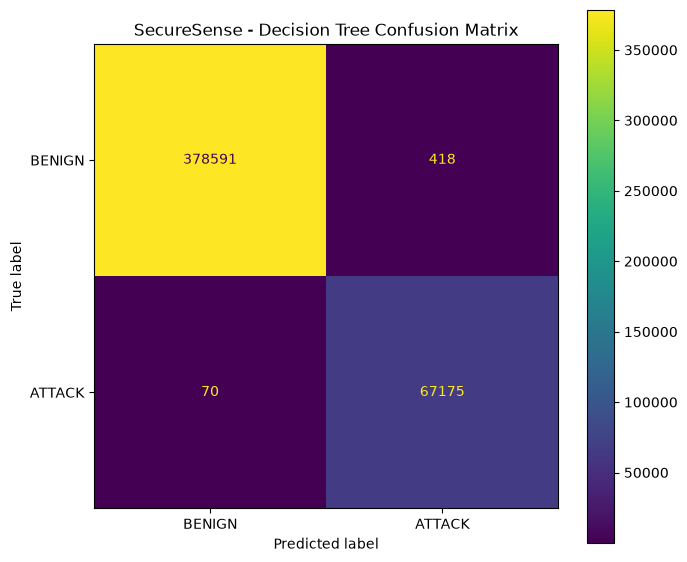

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "SecureSense - Decision Tree Confusion Matrix"
)

plt.tight_layout()
plt.show()

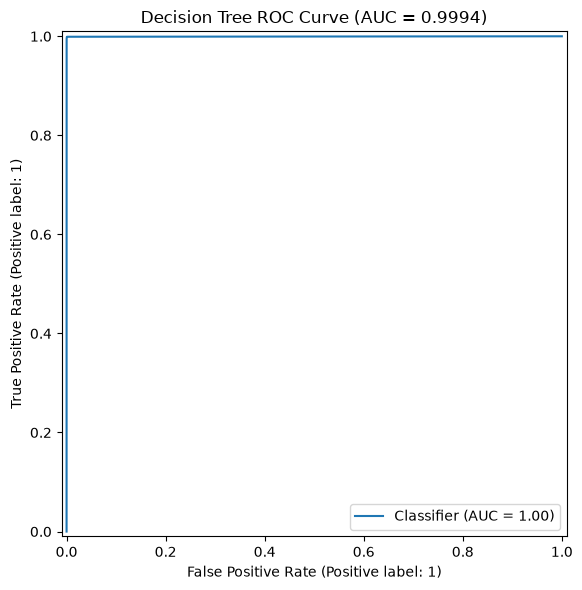

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title(
    f"Decision Tree ROC Curve (AUC = {roc_auc:.4f})"
)

plt.tight_layout()
plt.show()

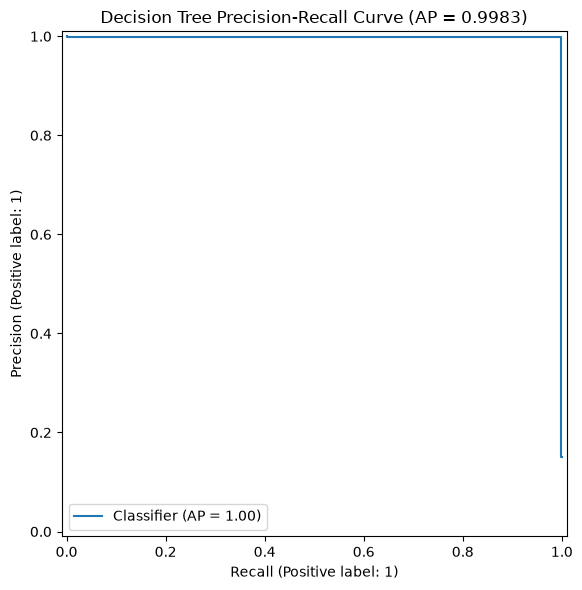

In [13]:
fig, ax = plt.subplots(figsize=(7, 6))

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob,
    ax=ax
)

ax.set_title(
    f"Decision Tree Precision-Recall Curve (AP = {pr_auc:.4f})"
)

plt.tight_layout()
plt.show()

In [14]:
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print("Top 20 important features:")
print(importance.head(20))

Top 20 important features:
Bwd Packet Length Std       0.564596
Bwd Packets/s               0.172271
Total Fwd Packets           0.072602
FIN Flag Count              0.029649
Init Fwd Win Bytes          0.019255
Avg Packet Size             0.018703
Bwd Packets Length Total    0.012068
Fwd IAT Total               0.012047
Init Bwd Win Bytes          0.010056
Avg Fwd Segment Size        0.009717
Packet Length Min           0.009394
Fwd IAT Mean                0.009071
Fwd Packet Length Max       0.006689
Avg Bwd Segment Size        0.005744
Bwd Header Length           0.005576
Fwd Seg Size Min            0.005149
Fwd IAT Min                 0.004907
PSH Flag Count              0.004867
Fwd Header Length           0.004297
URG Flag Count              0.003501
dtype: float64


In [15]:
import joblib

MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

model_path = os.path.join(
    MODEL_DIR,
    "decision_tree.pkl"
)

joblib.dump(
    model,
    model_path
)

print(f"Model saved to: {model_path}")

Model saved to: ../models\decision_tree.pkl


In [17]:
metrics = {
    "Model": "Decision Tree",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}

metrics_df = pd.DataFrame(
    [metrics]
)

metrics_path = (
    "../models/decision_tree_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

print("Metrics saved.")

metrics_df

Metrics saved.


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_Seconds
0,Decision Tree,0.998906,0.993816,0.998959,0.996381,0.999447,0.998317,170.49567


In [ ]:
# ============================================================
# SECURESENSE - FINAL GROUP-AWARE DECISION TREE
# ============================================================

import os
import time
import joblib
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

# ============================================================
# 1. EXACT FINAL GROUP-AWARE SPLIT PATHS
# ============================================================

TRAIN_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\train.parquet"

TEST_PATH = r"W:\FinalYearProject\SecureSense_Project\notebooks\data\final_group_splits\test.parquet"

MODEL_DIR = r"W:\FinalYearProject\SecureSense_Project\models"

RESULT_DIR = r"W:\FinalYearProject\SecureSense_Project\results"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

print("=" * 80)
print("SECURESENSE - FINAL GROUP-AWARE DECISION TREE")
print("=" * 80)

# ============================================================
# 2. CHECK FILES
# ============================================================

if not os.path.exists(TRAIN_PATH):
    raise FileNotFoundError(f"Training file not found:\n{TRAIN_PATH}")

if not os.path.exists(TEST_PATH):
    raise FileNotFoundError(f"Testing file not found:\n{TEST_PATH}")

print("\n✓ Training file found")
print("✓ Testing file found")

# ============================================================
# 3. LOAD DATA
# ============================================================

print("\nLoading training data...")
train_df = pd.read_parquet(TRAIN_PATH)

print("Loading testing data...")
test_df = pd.read_parquet(TEST_PATH)

print(f"\nTraining shape: {train_df.shape}")
print(f"Testing shape : {test_df.shape}")

# ============================================================
# 4. FEATURES AND TARGET
# ============================================================

TARGET = "BinaryLabel"

X_train = train_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

X_test = test_df.drop(
    columns=["BinaryLabel", "Label", "_source_file"],
    errors="ignore"
)

y_train = train_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

y_test = test_df[TARGET].map({
    "BENIGN": 0,
    "ATTACK": 1
})

print(f"\nNumber of features: {X_train.shape[1]}")

# ============================================================
# 5. VERIFY NO SOURCE-FILE OVERLAP
# ============================================================

train_sources = set(train_df["_source_file"].unique())
test_sources = set(test_df["_source_file"].unique())

overlap = train_sources.intersection(test_sources)

print("\nSource-file overlap:", len(overlap))

if overlap:
    raise ValueError(
        f"Source-file leakage detected: {overlap}"
    )

print("✓ No source-file overlap")

# ============================================================
# 6. TRAIN DECISION TREE
# ============================================================

print("\n" + "=" * 80)
print("TRAINING DECISION TREE")
print("=" * 80)

model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=20,
    min_samples_leaf=5,
    random_state=42
)

start_time = time.time()

model.fit(X_train, y_train)

training_time = time.time() - start_time

print(f"\nTraining completed in {training_time:.2f} seconds")

# ============================================================
# 7. PREDICTIONS
# ============================================================

print("\nGenerating predictions...")

y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

# ============================================================
# 8. METRICS
# ============================================================

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

pr_auc = average_precision_score(
    y_test,
    y_prob
)

print("\n" + "=" * 80)
print("FINAL DECISION TREE RESULTS")
print("=" * 80)

print(f"\nAccuracy  : {accuracy:.6f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.6f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.6f} ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.6f} ({f1 * 100:.2f}%)")
print(f"ROC-AUC   : {roc_auc:.6f} ({roc_auc * 100:.2f}%)")
print(f"PR-AUC    : {pr_auc:.6f} ({pr_auc * 100:.2f}%)")
print(f"Train Time: {training_time:.2f} seconds")

# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["BENIGN", "ATTACK"],
        digits=4,
        zero_division=0
    )
)

# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred
)

print("\n" + "=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["BENIGN", "ATTACK"]
)

disp.plot()

plt.title(
    "SecureSense - Final Decision Tree Confusion Matrix"
)

plt.tight_layout()
plt.show()

# ============================================================
# 11. ROC CURVE
# ============================================================

RocCurveDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(
    "SecureSense - Final Decision Tree ROC Curve"
)

plt.tight_layout()
plt.show()

# ============================================================
# 12. PRECISION-RECALL CURVE
# ============================================================

PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob
)

plt.title(
    "SecureSense - Final Decision Tree Precision-Recall Curve"
)

plt.tight_layout()
plt.show()

# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n" + "=" * 80)
print("TOP 20 IMPORTANT FEATURES")
print("=" * 80)

print(
    feature_importance
    .head(20)
    .to_string(index=False)
)

# ============================================================
# 14. SAVE FEATURE IMPORTANCE
# ============================================================

importance_path = os.path.join(
    RESULT_DIR,
    "final_decision_tree_feature_importance.csv"
)

feature_importance.to_csv(
    importance_path,
    index=False
)

# ============================================================
# 15. SAVE MODEL
# ============================================================

model_path = os.path.join(
    MODEL_DIR,
    "final_decision_tree.pkl"
)

joblib.dump(
    model,
    model_path
)

# ============================================================
# 16. SAVE METRICS
# ============================================================

metrics = pd.DataFrame([{
    "Model": "Decision Tree",
    "Evaluation": "Final Group-Aware",
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "ROC_AUC": roc_auc,
    "PR_AUC": pr_auc,
    "Training_Time_Seconds": training_time
}])

metrics_path = os.path.join(
    RESULT_DIR,
    "final_decision_tree_metrics.csv"
)

metrics.to_csv(
    metrics_path,
    index=False
)

# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 80)
print("FINAL DECISION TREE COMPLETED")
print("=" * 80)

print(f"\nModel saved:")
print(model_path)

print(f"\nMetrics saved:")
print(metrics_path)

print(f"\nFeature importance saved:")
print(importance_path)

print("\nFinal Metrics:")
print(metrics.to_string(index=False))

print("\n✓ Evaluated on completely unseen source files.")
print("✓ No source-file leakage.")